# Gene signatures around the tumor: polar enrichment maps

A SCOMV polar histogram only needs one non-negative weight per grid square, so a **signature score** (several genes
together) can be mapped around the tumor boundary exactly like one gene's counts. This tutorial shows

1. a **gene list of your own** → its polar enrichment map (`scomv.signature_polar_enrichment`), and
2. **all MSigDB Hallmark gene sets** → the polar maps of the significantly enriched ones
   (`scomv.hallmark_polar_enrichment`, `scomv.plot_significant_hallmarks`).

Method (one call does all steps):

1. Score per 10 µm grid square: counts / total counts × median total → log1p → z-score per gene over the tissue squares
   → mean z of the member genes, clipped at 0.
2. Polar cells: `r_step` µm rings from the boundary out to `r_max` µm × **30° sectors** (fixed). The boundary squares
   (distance 0) are not "outside". With `include_inside=True` the tumor itself (every square with distance < 1 µm) is
   one extra cell, drawn as the centre disc.
3. $\log_2 E_c = \log_2 \frac{S_c / \sum S}{T_c / \sum T}$: the signature's share of a polar cell relative to the
   tissue's share ($T$ = number of tissue squares).
4. Null: random gene sets of the same size from the same expression deciles (`n_perm` per signature); one-sided
   empirical p per cell, BH within the signature (`q`) and across all signatures × cells (`q_global`).
   Black frame = q < 0.05 and enriched; grey = too little tissue to test.

## 1. Data and SCOMV (same steps as the gene_analysis tutorial)

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import stlearn as st
import scomv
from scomv.preparation.skny_calc_distance import calculate_distance

adata = st.ReadXenium(
    feature_cell_matrix_file="../tutorial_data/xenium_data/cell_feature_matrix.h5",
    cell_summary_file="../tutorial_data/xenium_data/cells.csv.gz",
    library_id="example data", image_path=None, scale=1, spot_diameter_fullres=10,
)
sc.pp.filter_genes(adata, min_cells=300)

# 10 µm grid and SKNY tumor boundary (CDH1 / EPCAM)
N_COL = int((adata.obs.imagecol.max() - adata.obs.imagecol.min()) / 10)
N_ROW = int((adata.obs.imagerow.max() - adata.obs.imagerow.min()) / 10)
grid = st.tl.cci.grid(adata, n_row=N_ROW, n_col=N_COL, n_cpus=10, verbose=False)
grid = calculate_distance(grid, pos_marker_ls=["CDH1", "EPCAM"])
sc.pp.filter_cells(adata, min_genes=10)

[calculate_distance] N_ROW=547, N_COL=752, positive cells in grid=100012/411344


In [2]:
from scomv.preparation.choose_roi import add_distance_regions

grid = add_distance_regions(grid)          # distance band of every grid square (used by extract_roi)

# SCOMV for one ROI: polar histogram of every gene, MINAS distance, PCoA
gene_pipe = scomv.SCOMVPipeline(adata=adata, grid=grid, bin_size=10)
gene_out = gene_pipe.run(roi=(2400, 3400, 2400, 3800))
print(f"{len(gene_pipe.selected_genes)} genes in the ROI")

312 genes in the ROI


## 2. Your own gene list

Pass a list of genes (or a dict `{name: genes}` for several signatures). `r_max` sets the outer distance and
`include_inside` adds the tumor as one cell.

1 signature(s) x 20,000 permutations, 57 / 72 polar cells tested (0 s)


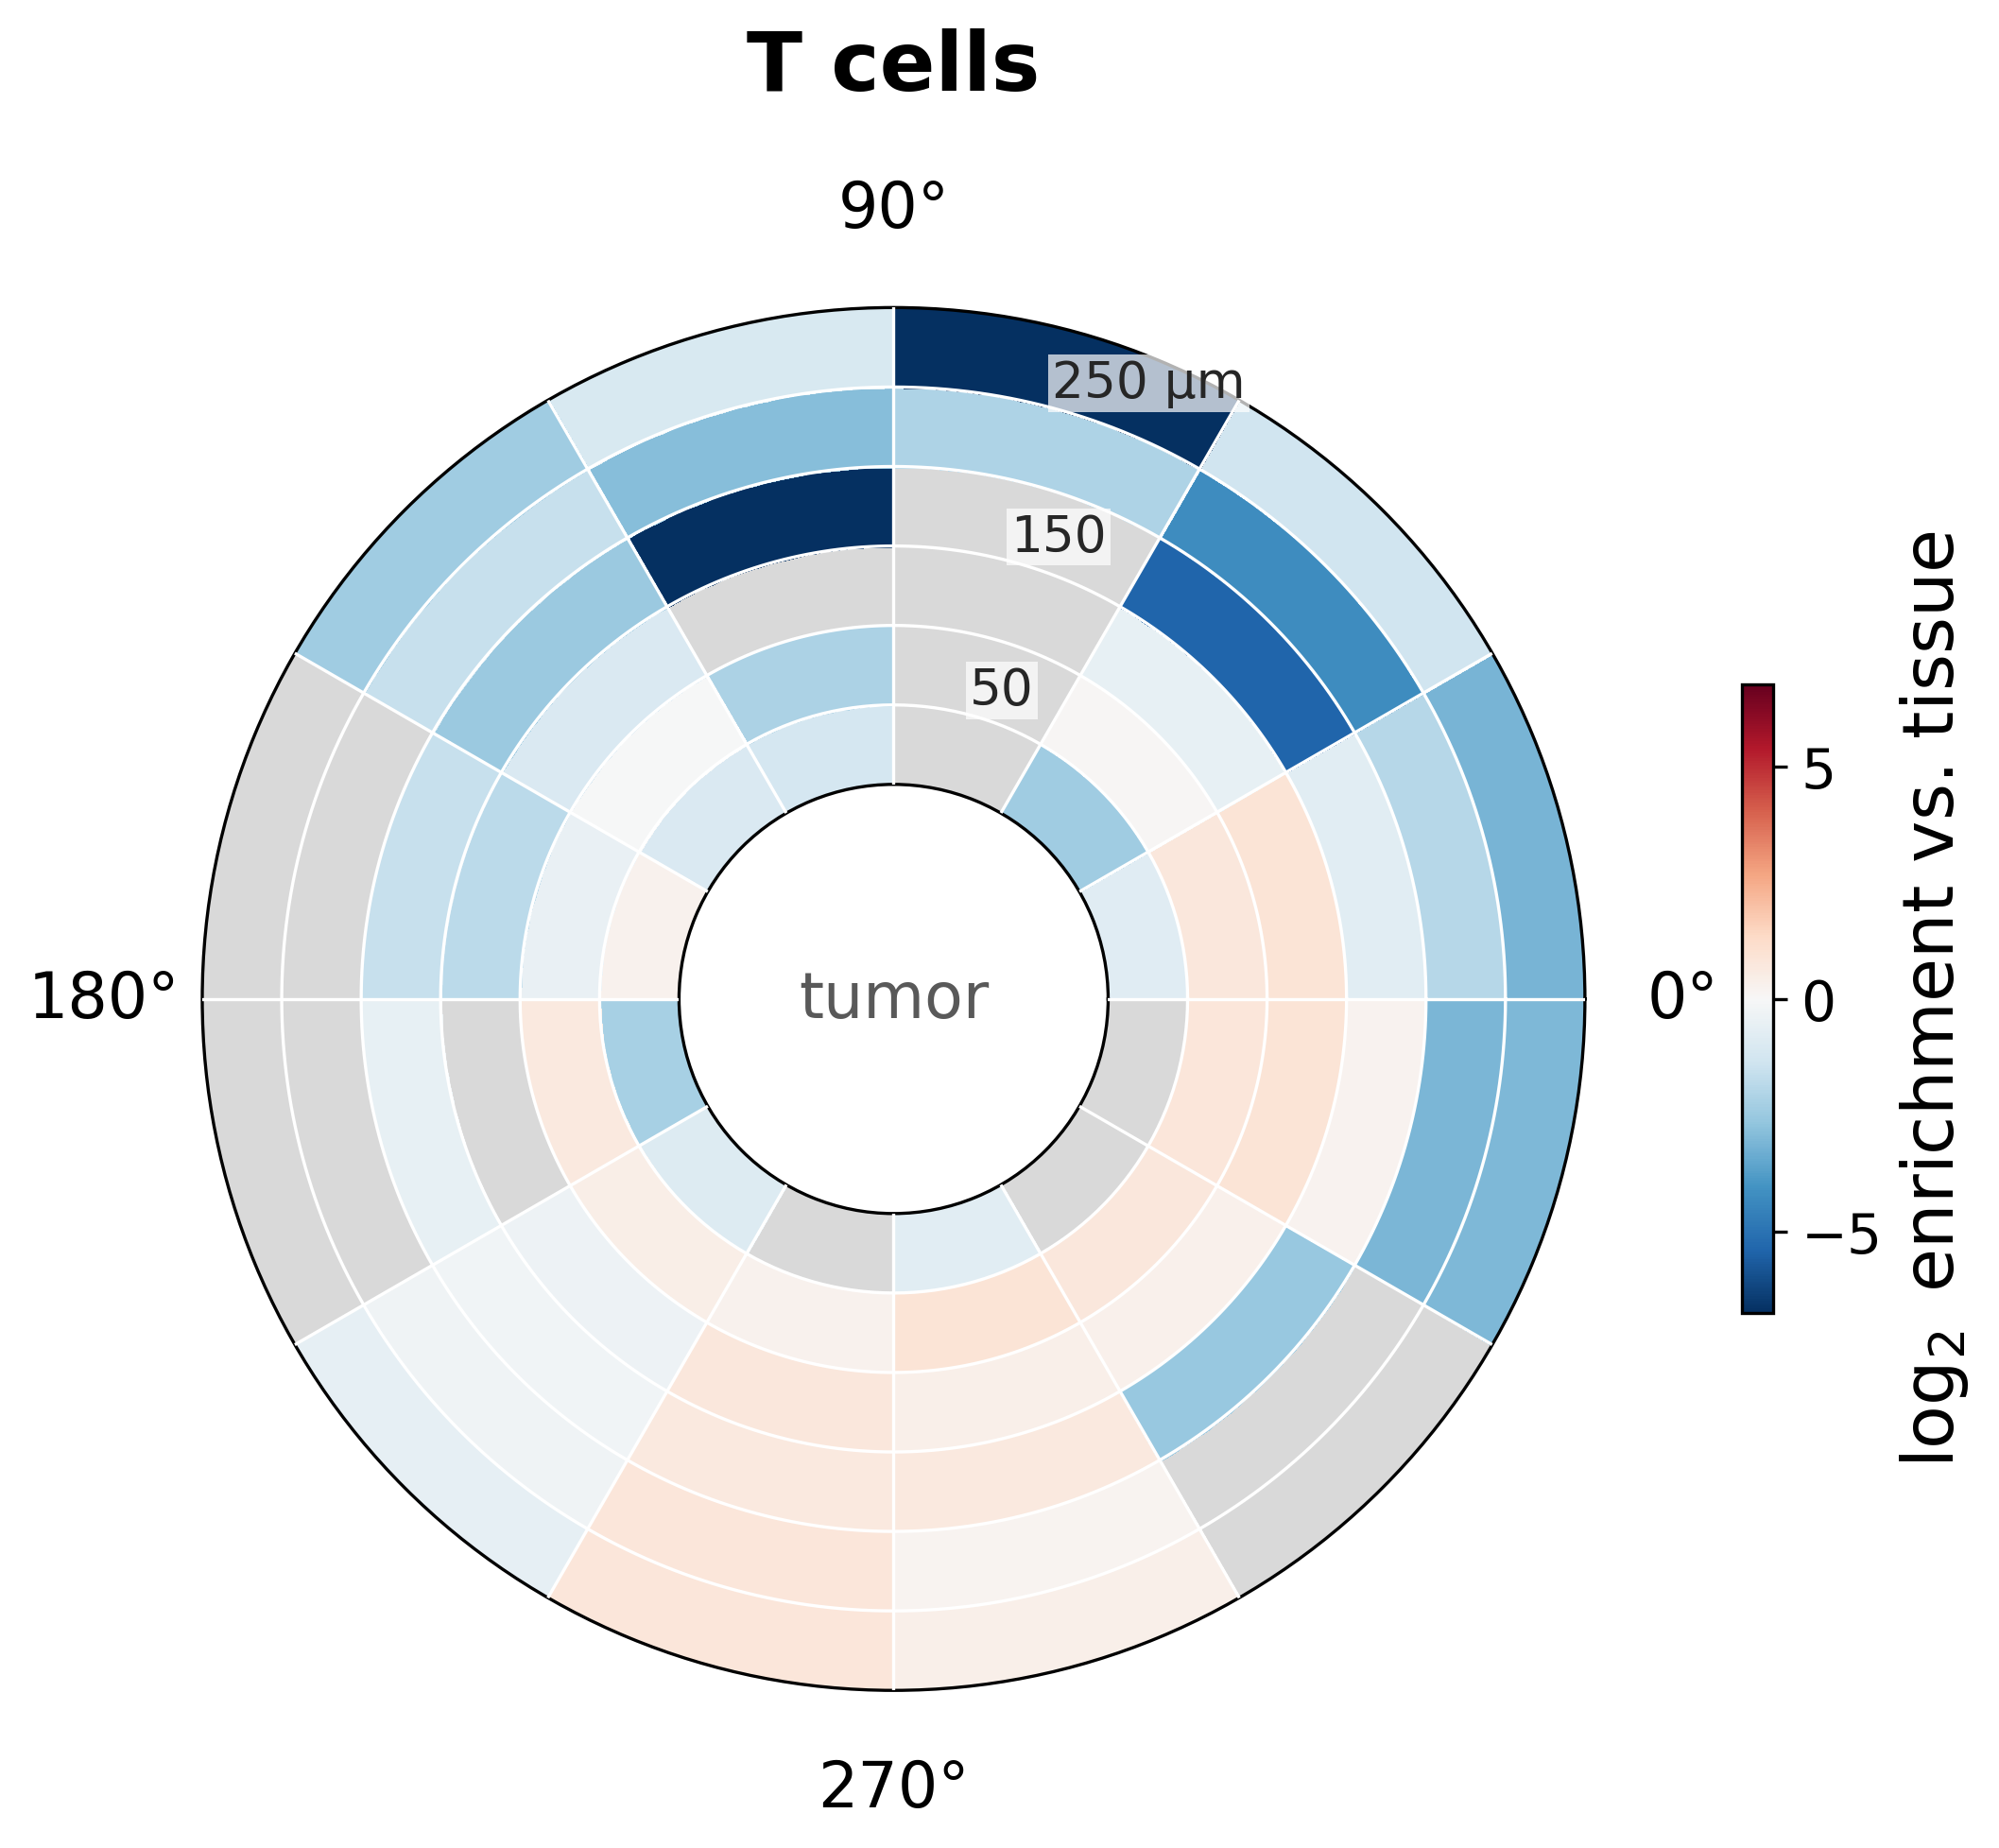

,n_genes,n_sig_cells,n_sig_cells_global,min_p,best_cell,best_log2E,best_z,best_q,best_q_global
signature,,,,,,,,,
T cells,7,0,0,0.0024,"50-100 µm, 0-30°",0.779324,2.084119,0.136793,0.136793


In [3]:
T_CELL = ["CD3E", "CD3D", "CD247", "CD8A", "CD4", "GZMA", "TRAC"]

res_t = scomv.signature_polar_enrichment(gene_pipe, T_CELL, name="T cells", r_max=300, r_step=50,
                                         include_inside=False)
scomv.plot_signature_polar(res_t)
plt.show()
res_t.summary()

The same genes up to 150 µm, with the tumor inside as one cell (centre disc; black ring = significant):

2 signature(s) x 20,000 permutations, 29 / 37 polar cells tested (1 s)


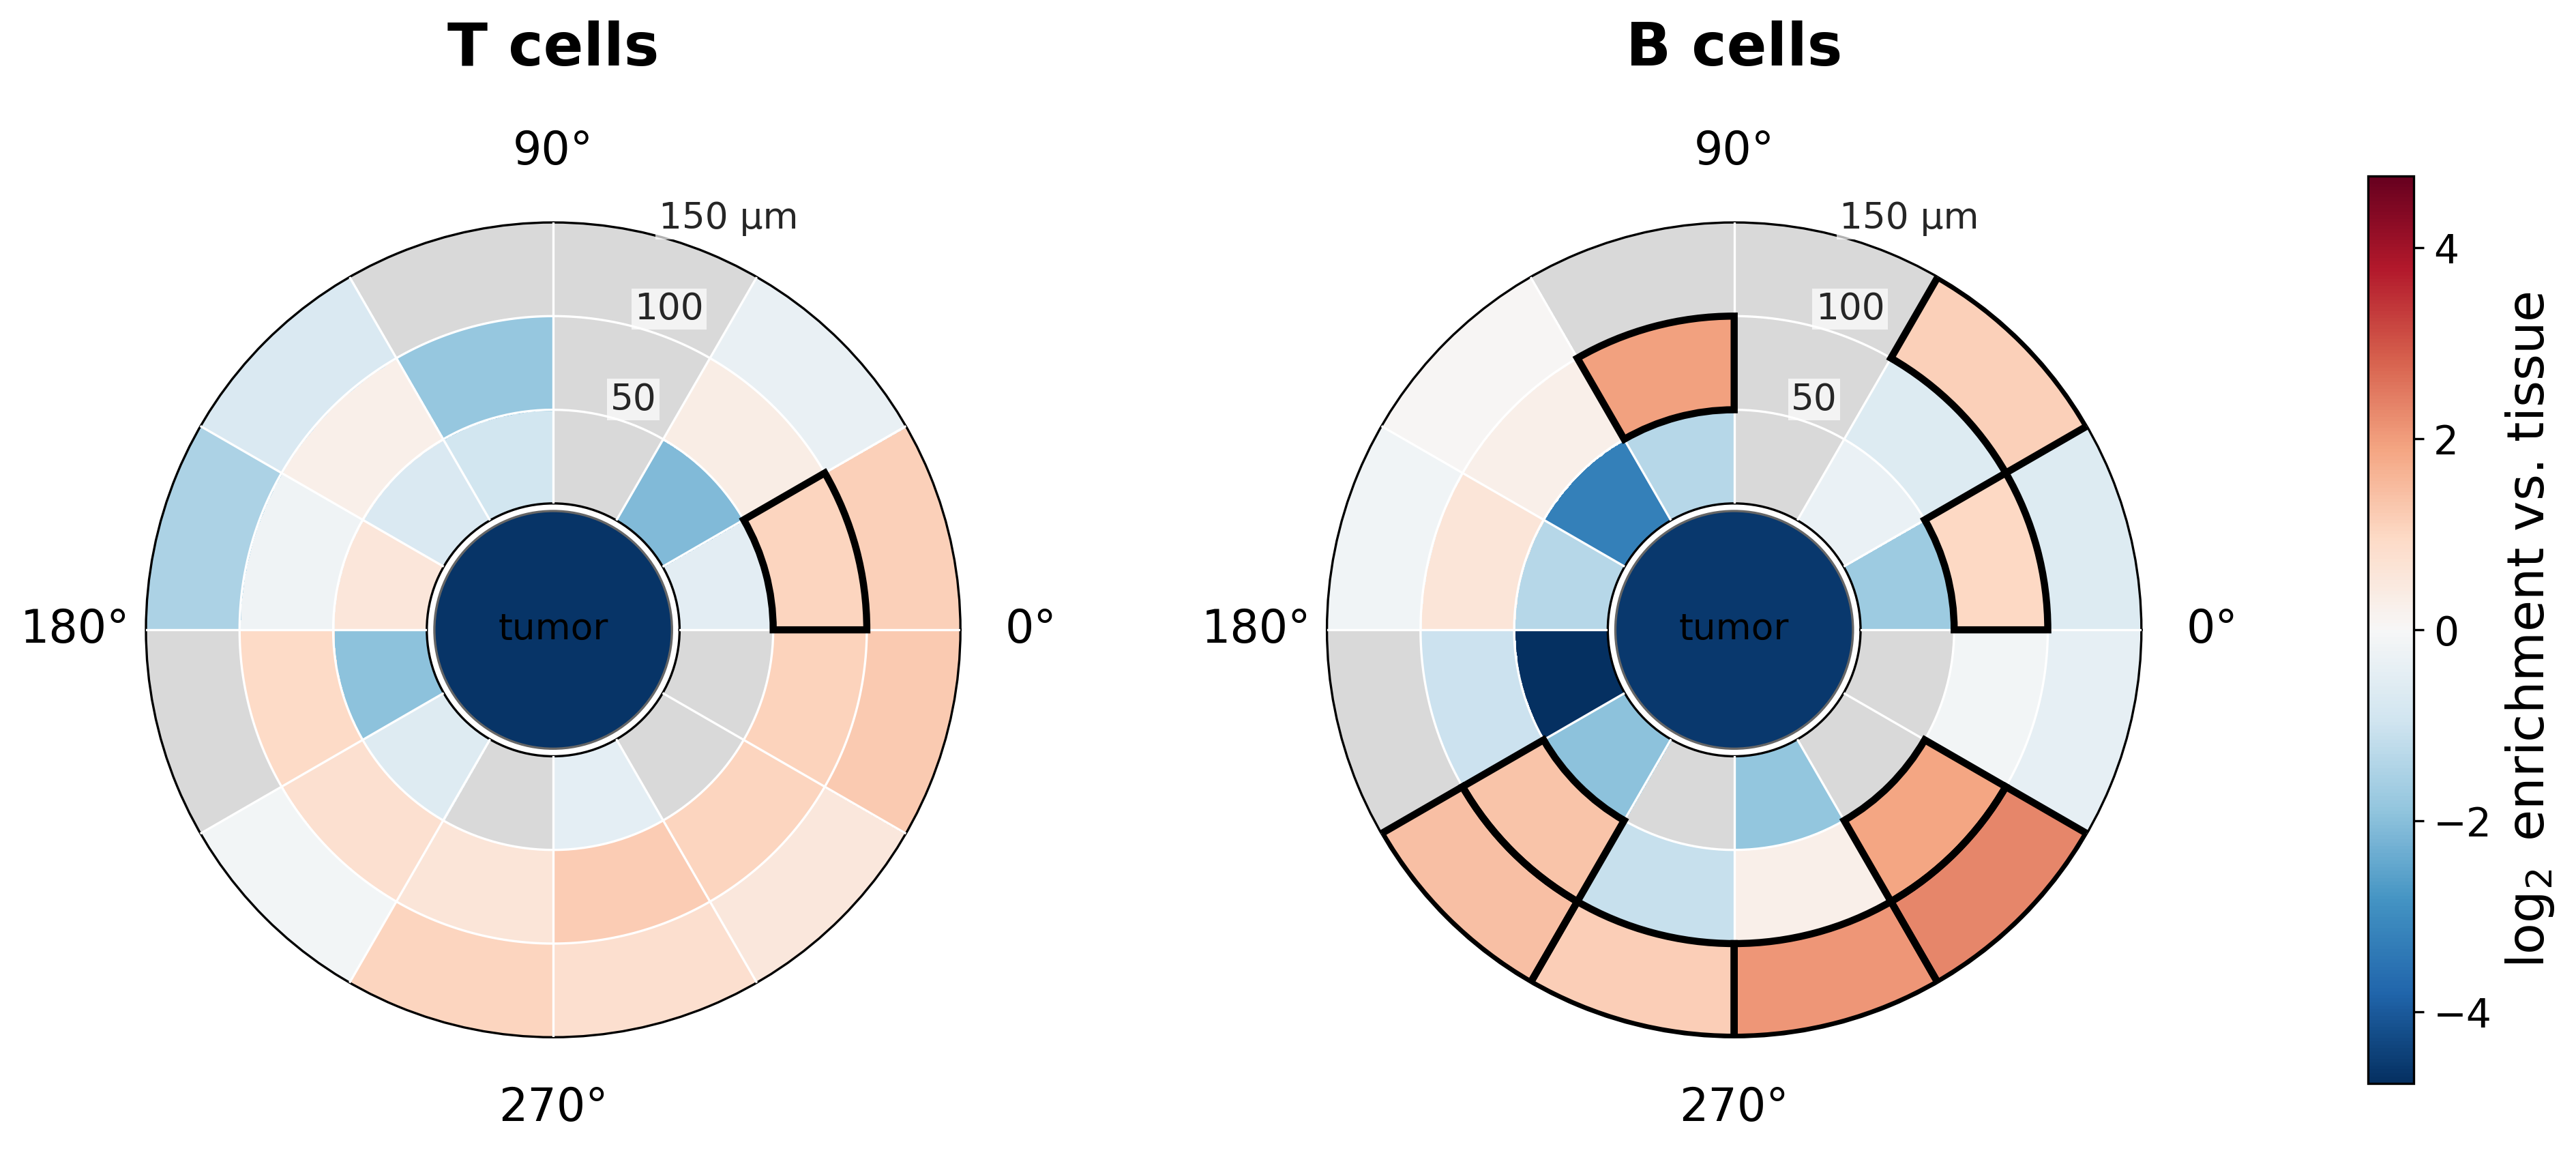

,signature,cell,n_tissue_squares,valid,log2_enrichment,z,p,q,q_global
0,T cells,inside,459.000000,True,-4.664460,-2.376318,0.971501,0.988101,1.0
1,T cells,"0-50 µm, -180--150°",37.500000,True,-1.946974,-2.552154,0.988101,0.988101,1.0
2,T cells,"0-50 µm, -150--120°",26.833333,True,-0.616169,-0.665852,0.760412,0.988101,1.0
3,T cells,"0-50 µm, -120--90°",13.833333,False,NaN,NaN,NaN,NaN,NaN
4,T cells,"0-50 µm, -90--60°",46.666667,True,-0.479763,-0.958449,0.844058,0.988101,1.0
5,T cells,"0-50 µm, -60--30°",12.000000,False,NaN,NaN,NaN,NaN,NaN
6,T cells,"0-50 µm, -30-0°",10.000000,False,NaN,NaN,NaN,NaN,NaN
7,T cells,"0-50 µm, 0-30°",62.500000,True,-0.507358,-0.464725,0.677216,0.988101,1.0


In [4]:
res_t_in = scomv.signature_polar_enrichment(gene_pipe, {"T cells": T_CELL,
                                                        "B cells": ["MS4A1", "CD79A", "BANK1", "CD19", "TCL1A"]},
                                            r_max=150, r_step=50, include_inside=True, min_set_genes=3)
scomv.plot_signature_polar(res_t_in, ncols=2)
plt.show()
res_t_in.table().query("signature == 'T cells'").head(8)

`scomv.signature_polar_histogram` gives the plain score-weighted polar histogram over the full radius range
(-150 to 300 µm), like the per-gene histograms of SCOMV:

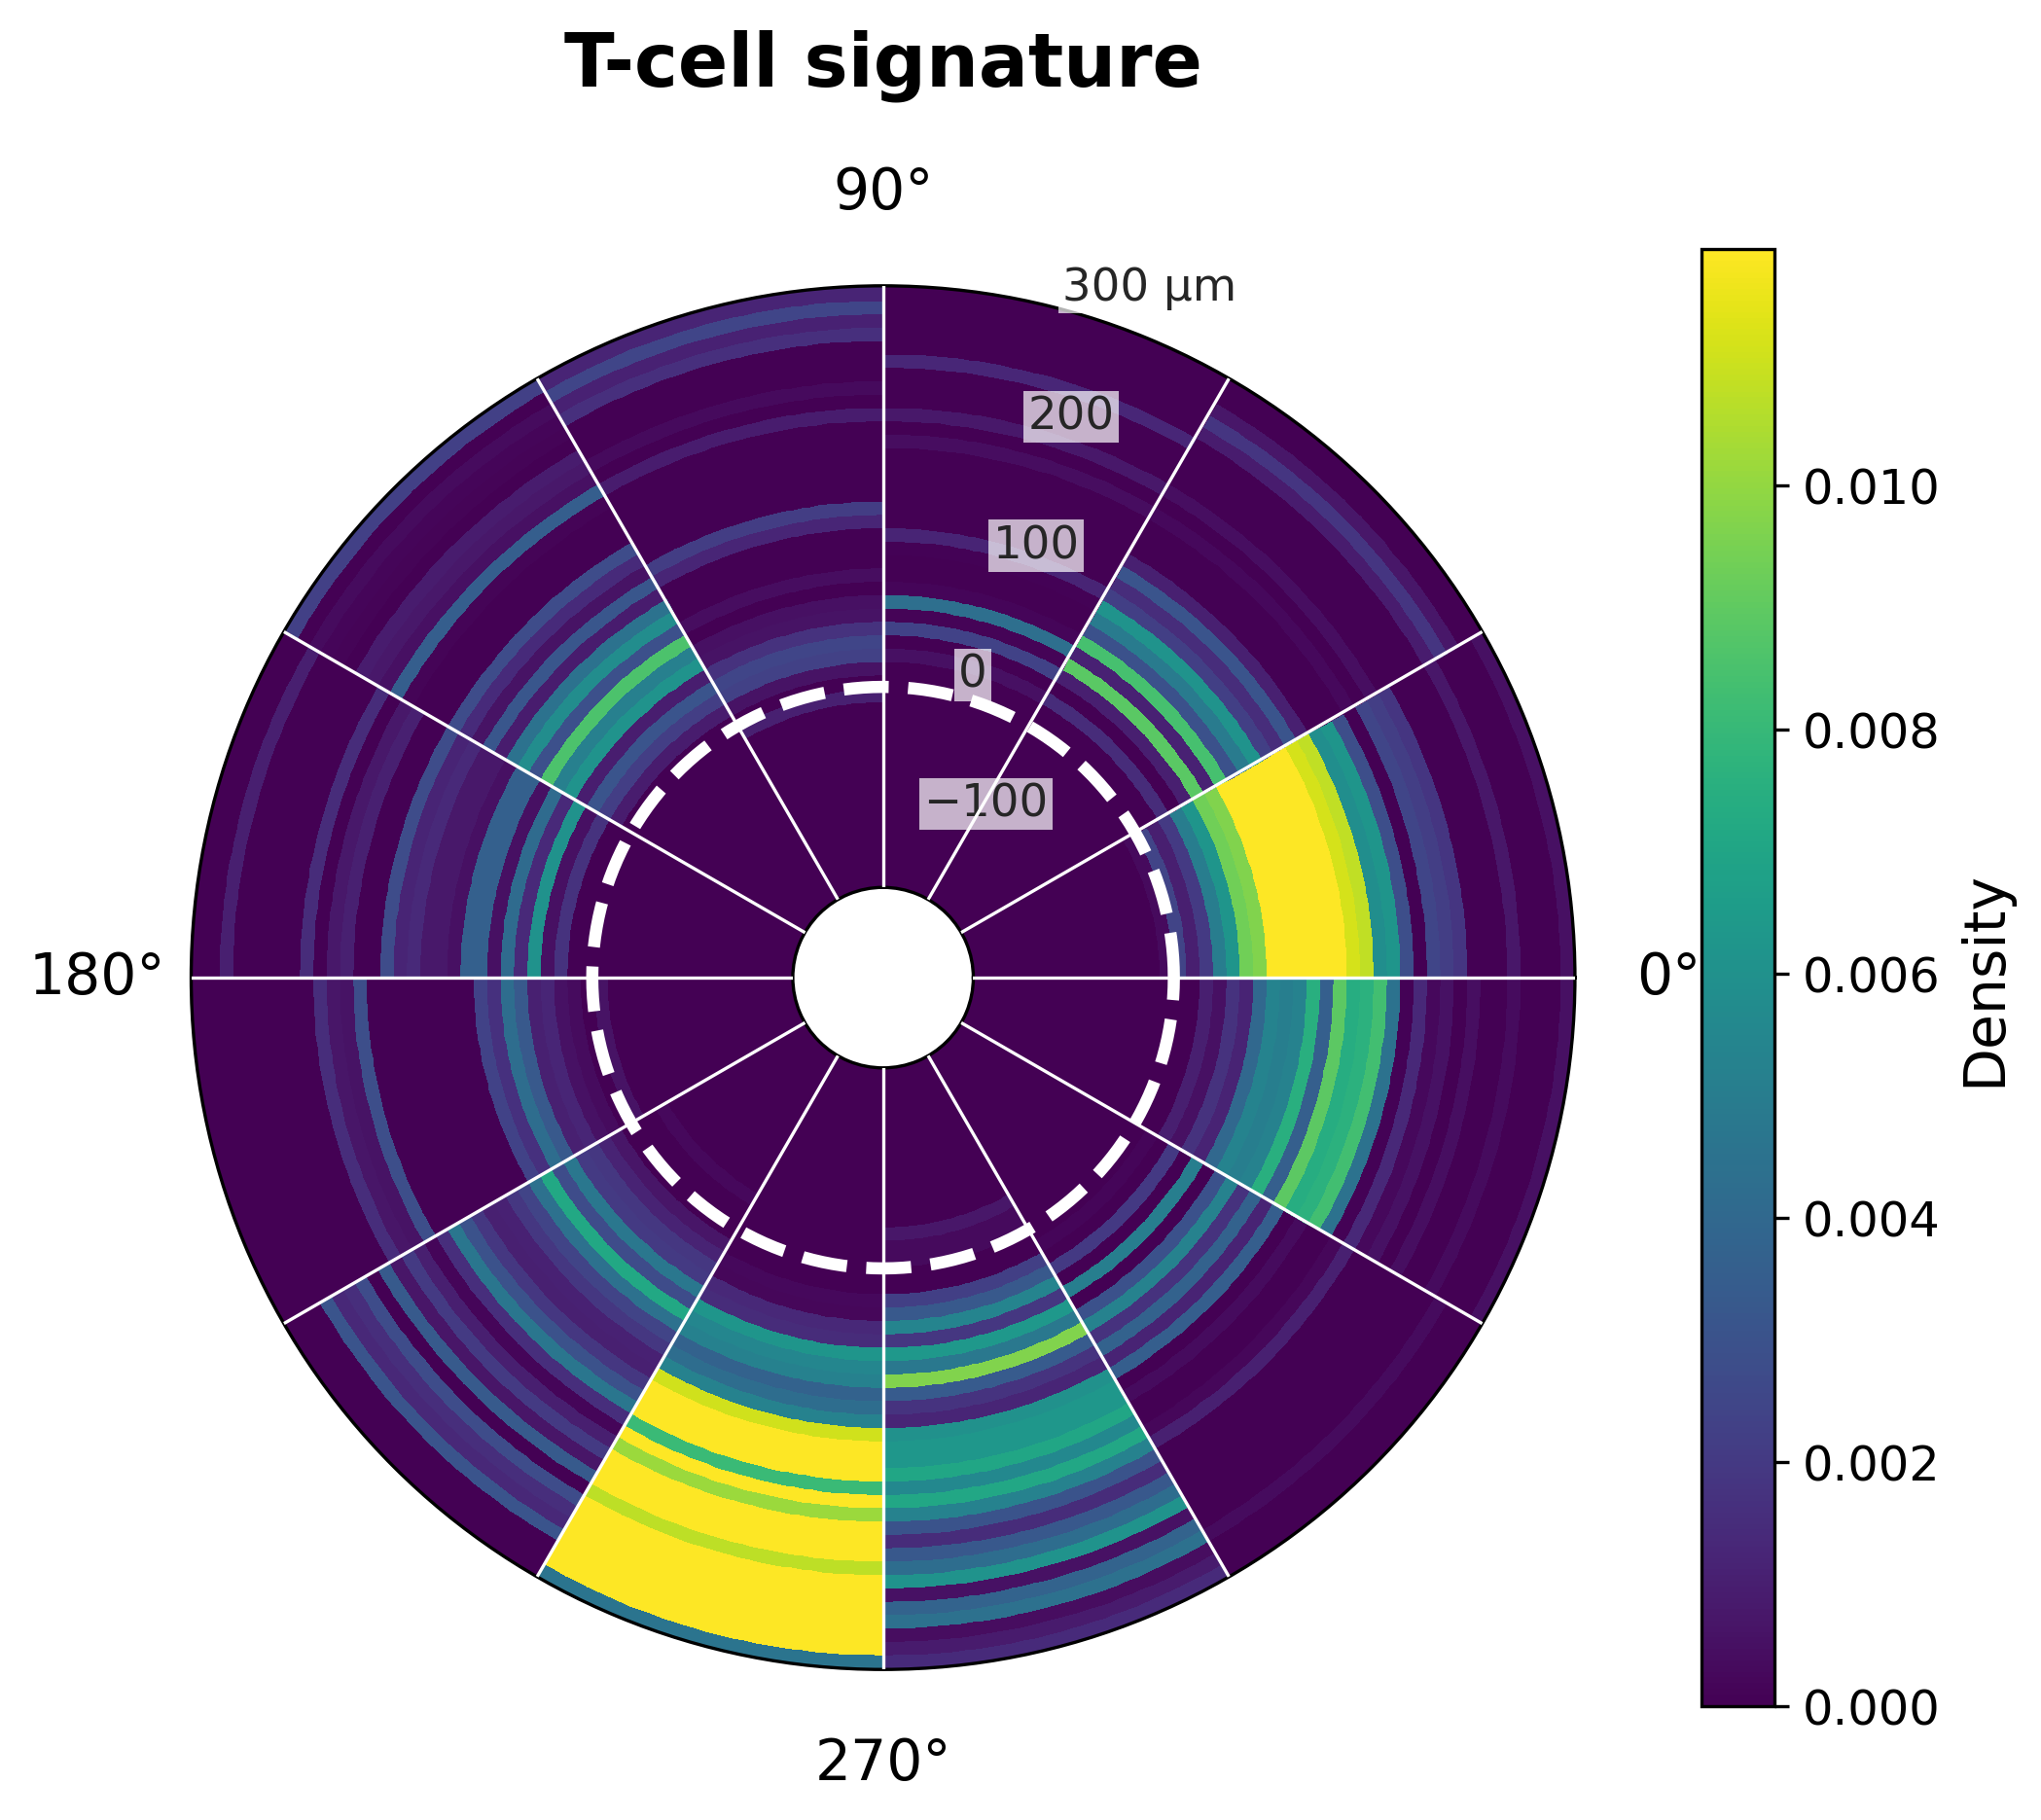

In [5]:
from scomv.polar_plot import plot_polar_heatmap

A = scomv.signature_polar_histogram(gene_pipe, T_CELL)
RB, AB = np.arange(-150, 310, 10), np.arange(-180, 181, 30)
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": "polar"})
plot_polar_heatmap(A, RB, AB, ax=ax, vmin=0, vmax=A.max() * 0.5, radius_ticks=[-100, 0, 100, 200, 300],
                   cbar_label="Density", title="T-cell signature")
plt.show()

## 3. MSigDB Hallmark: significant pathways only

All Hallmark sets with ≥ 5 genes of the panel are tested (the 312-gene panel covers 29 of the 50 sets). The gene
sets are downloaded from MSigDB once (`gseapy`, network) and cached in `hallmark_2024.1.Hs.json`. The figure shows
only the sets with at least one significant cell after BH across all sets × cells (`q_global`).

In [6]:
R_MAX = 150            # outer distance (µm)
INCLUDE_INSIDE = True  # tumor inside as one cell

hm = scomv.hallmark_polar_enrichment(gene_pipe, r_max=R_MAX, include_inside=INCLUDE_INSIDE,
                                     cache="hallmark_2024.1.Hs.json")
hm.summary().head(10)

29 signature(s) x 20,000 permutations, 29 / 37 polar cells tested (13 s); skipped (< 5 panel genes): {'APICAL_SURFACE': 3, 'BILE_ACID_METABOLISM': 1, 'DNA_REPAIR': 0, 'E2F_TARGETS': 3, 'FATTY_ACID_METABOLISM': 3, 'HEDGEHOG_SIGNALING': 0, 'INTERFERON_ALPHA_RESPONSE': 1, 'MYC_TARGETS_V1': 1, 'MYC_TARGETS_V2': 1, 'NOTCH_SIGNALING': 1, 'OXIDATIVE_PHOSPHORYLATION': 2, 'PANCREAS_BETA_CELLS': 0, 'PEROXISOME': 1, 'PI3K_AKT_MTOR_SIGNALING': 3, 'PROTEIN_SECRETION': 3, 'REACTIVE_OXYGEN_SPECIES_PATHWAY': 1, 'SPERMATOGENESIS': 0, 'TGF_BETA_SIGNALING': 1, 'UNFOLDED_PROTEIN_RESPONSE': 2, 'UV_RESPONSE_UP': 4, 'WNT_BETA_CATENIN_SIGNALING': 1}


,n_genes,n_sig_cells,n_sig_cells_global,min_p,best_cell,best_log2E,best_z,best_q,best_q_global,inside_log2E,inside_sig,category
signature,,,,,,,,,,,,
INFLAMMATORY_RESPONSE,12,3,1,0.000100,"100-150 µm, 0-30°",1.690666,2.448829,0.002900,0.042048,-2.325117,False,immune
TNFA_SIGNALING_VIA_NFKB,15,1,1,0.000050,"100-150 µm, 0-30°",1.735880,2.660156,0.001450,0.042048,-0.529835,False,signaling
ALLOGRAFT_REJECTION,24,2,0,0.000250,"50-100 µm, -90--60°",1.422160,2.299345,0.005800,0.052560,-4.052828,False,immune
IL2_STAT5_SIGNALING,13,2,0,0.001050,"100-150 µm, 0-30°",1.558127,2.263891,0.021749,0.126144,-3.029149,False,signaling
IL6_JAK_STAT3_SIGNALING,8,2,0,0.000200,"100-150 µm, -30-0°",1.753494,2.230911,0.005800,0.052560,-1.078883,False,immune
ANGIOGENESIS,5,1,0,0.001050,"0-50 µm, -150--120°",1.665772,2.128199,0.030448,0.110376,-2.780544,False,development
ESTROGEN_RESPONSE_EARLY,13,1,0,0.000600,inside,1.531566,1.433061,0.017399,0.084096,1.531566,False,signaling
ADIPOGENESIS,7,0,0,0.012999,"0-50 µm, -150--120°",0.867139,1.833379,0.376981,0.366417,0.725318,False,development
ANDROGEN_RESPONSE,6,0,0,0.009300,inside,1.503543,1.208881,0.269687,0.329656,1.503543,False,signaling


2 / 29 signatures with >= 1 significant cell (q_global < 0.05)


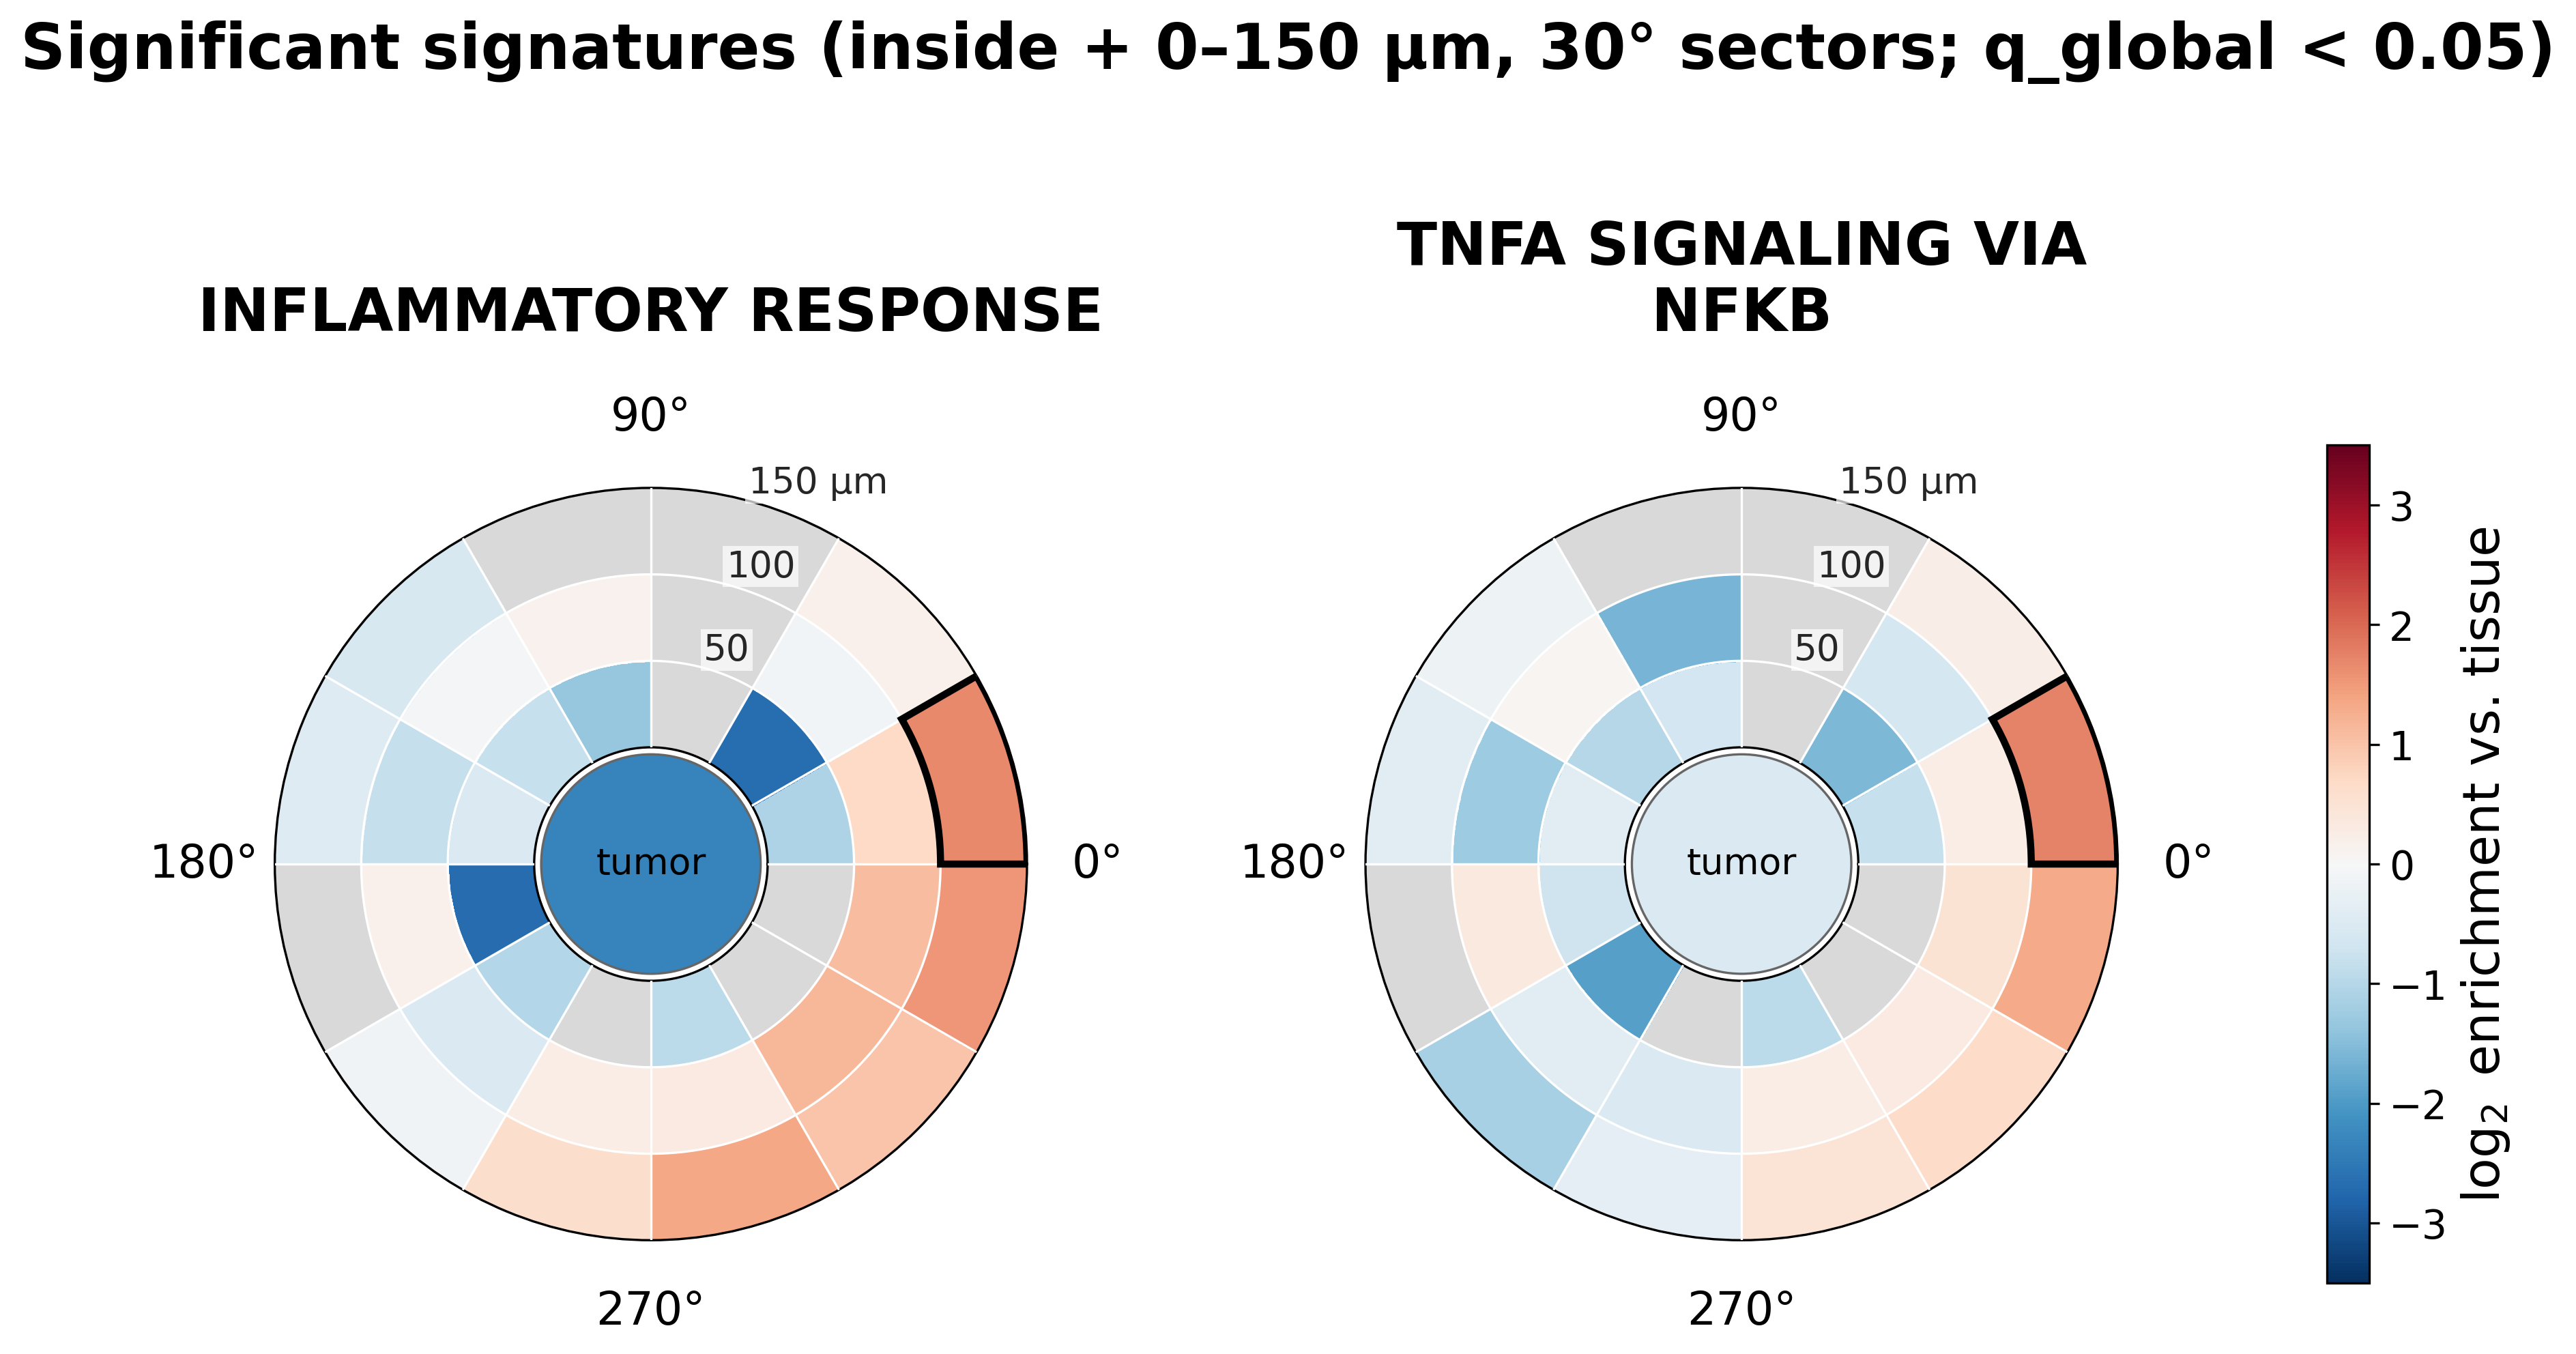

In [7]:
figs = scomv.plot_significant_hallmarks(hm)            # BH across all signatures x cells
plt.show()

With BH within each signature (`q_key="q"`) more cells pass — appropriate for a few pre-selected signatures, not for a
search over all sets. `by_category=True` draws one figure per Hallmark process category.

7 / 29 signatures with >= 1 significant cell (q < 0.05)


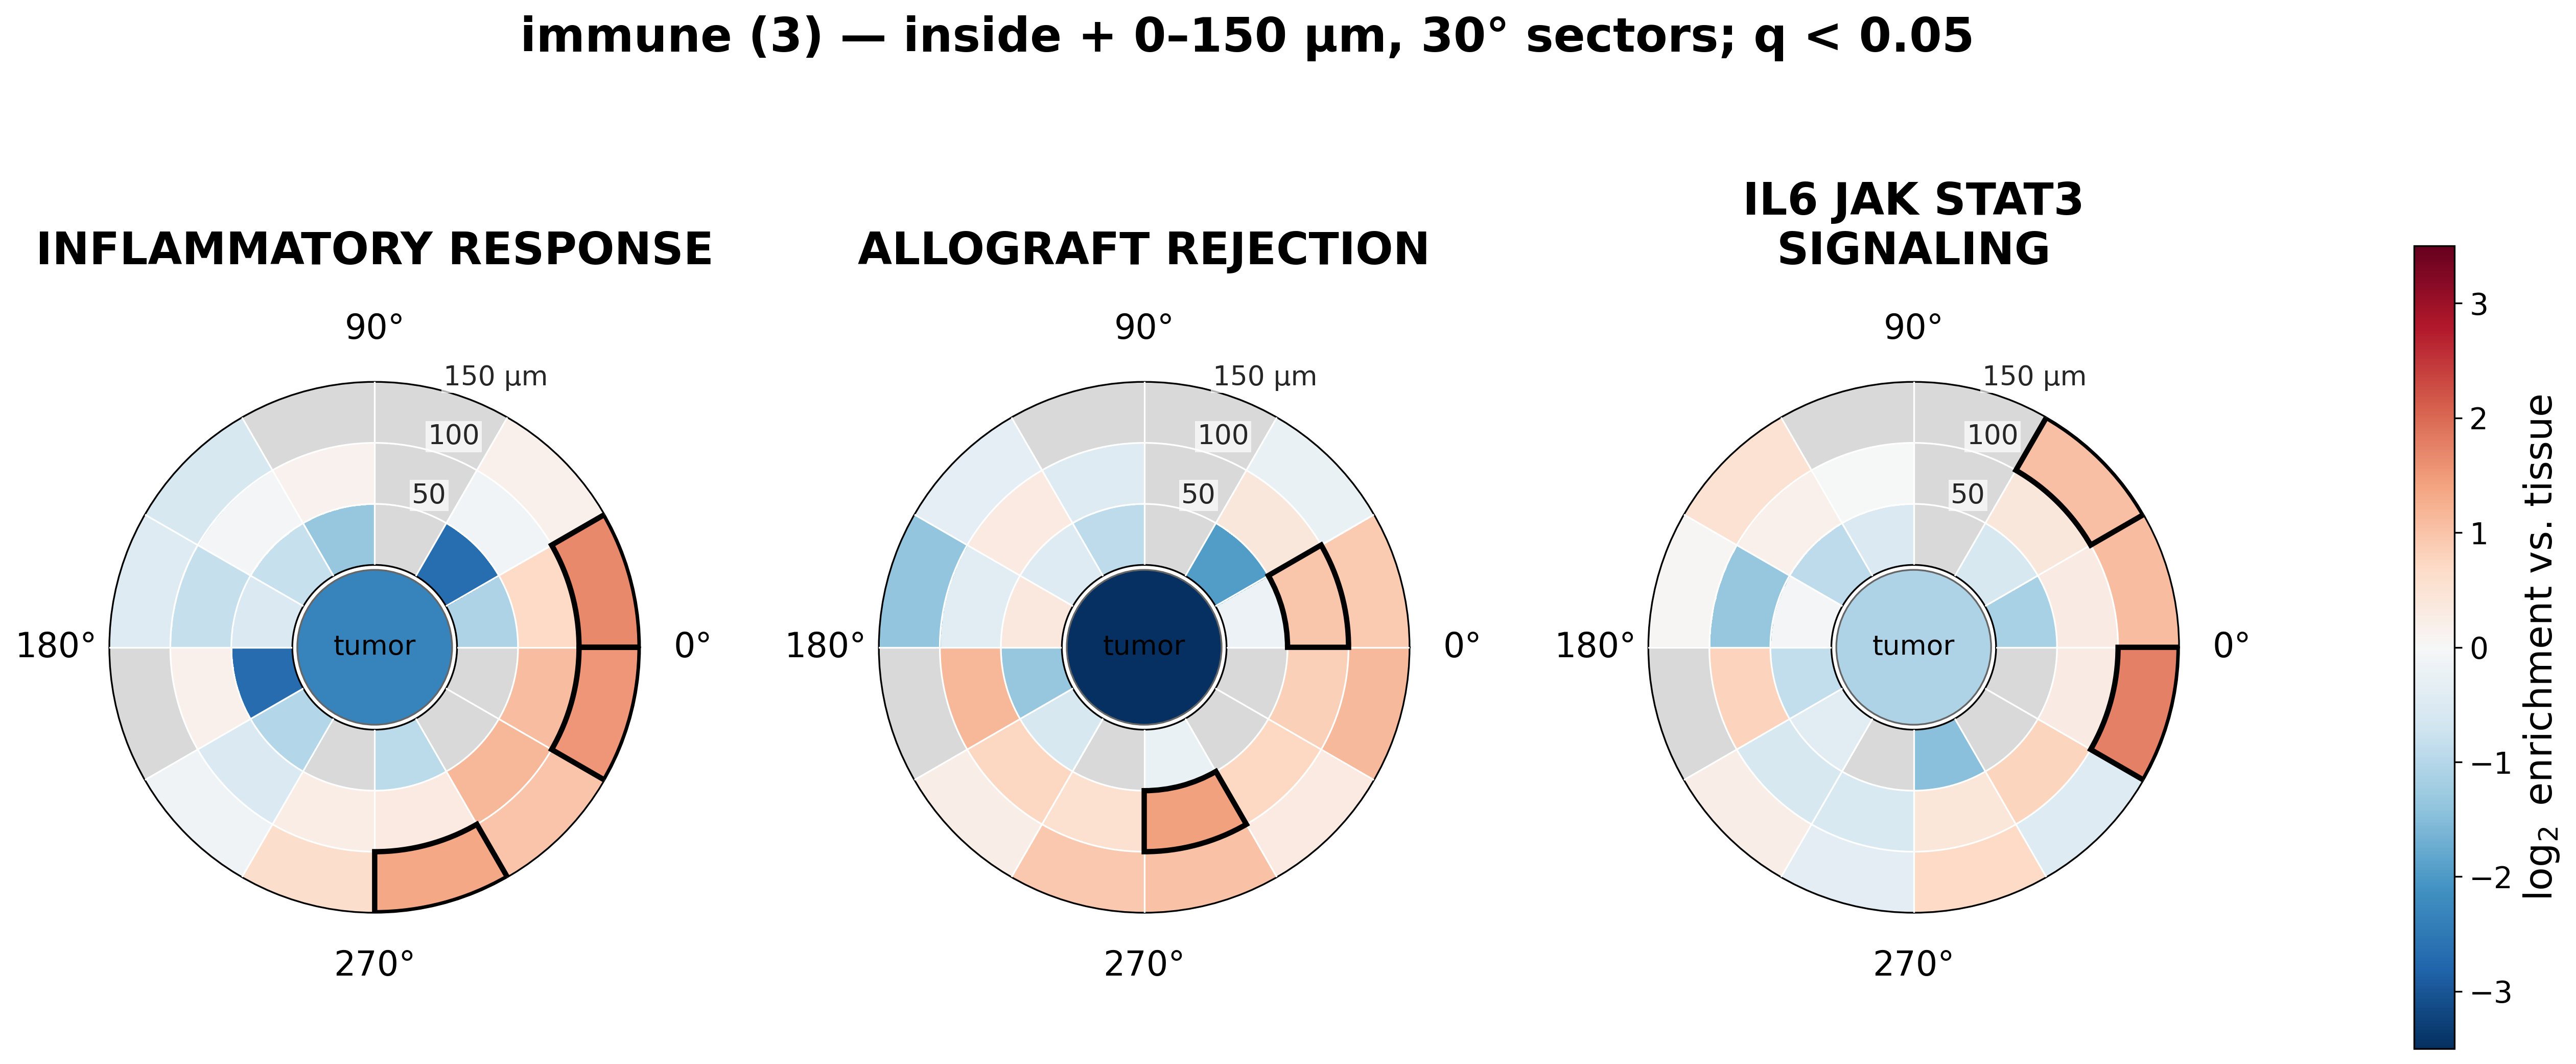

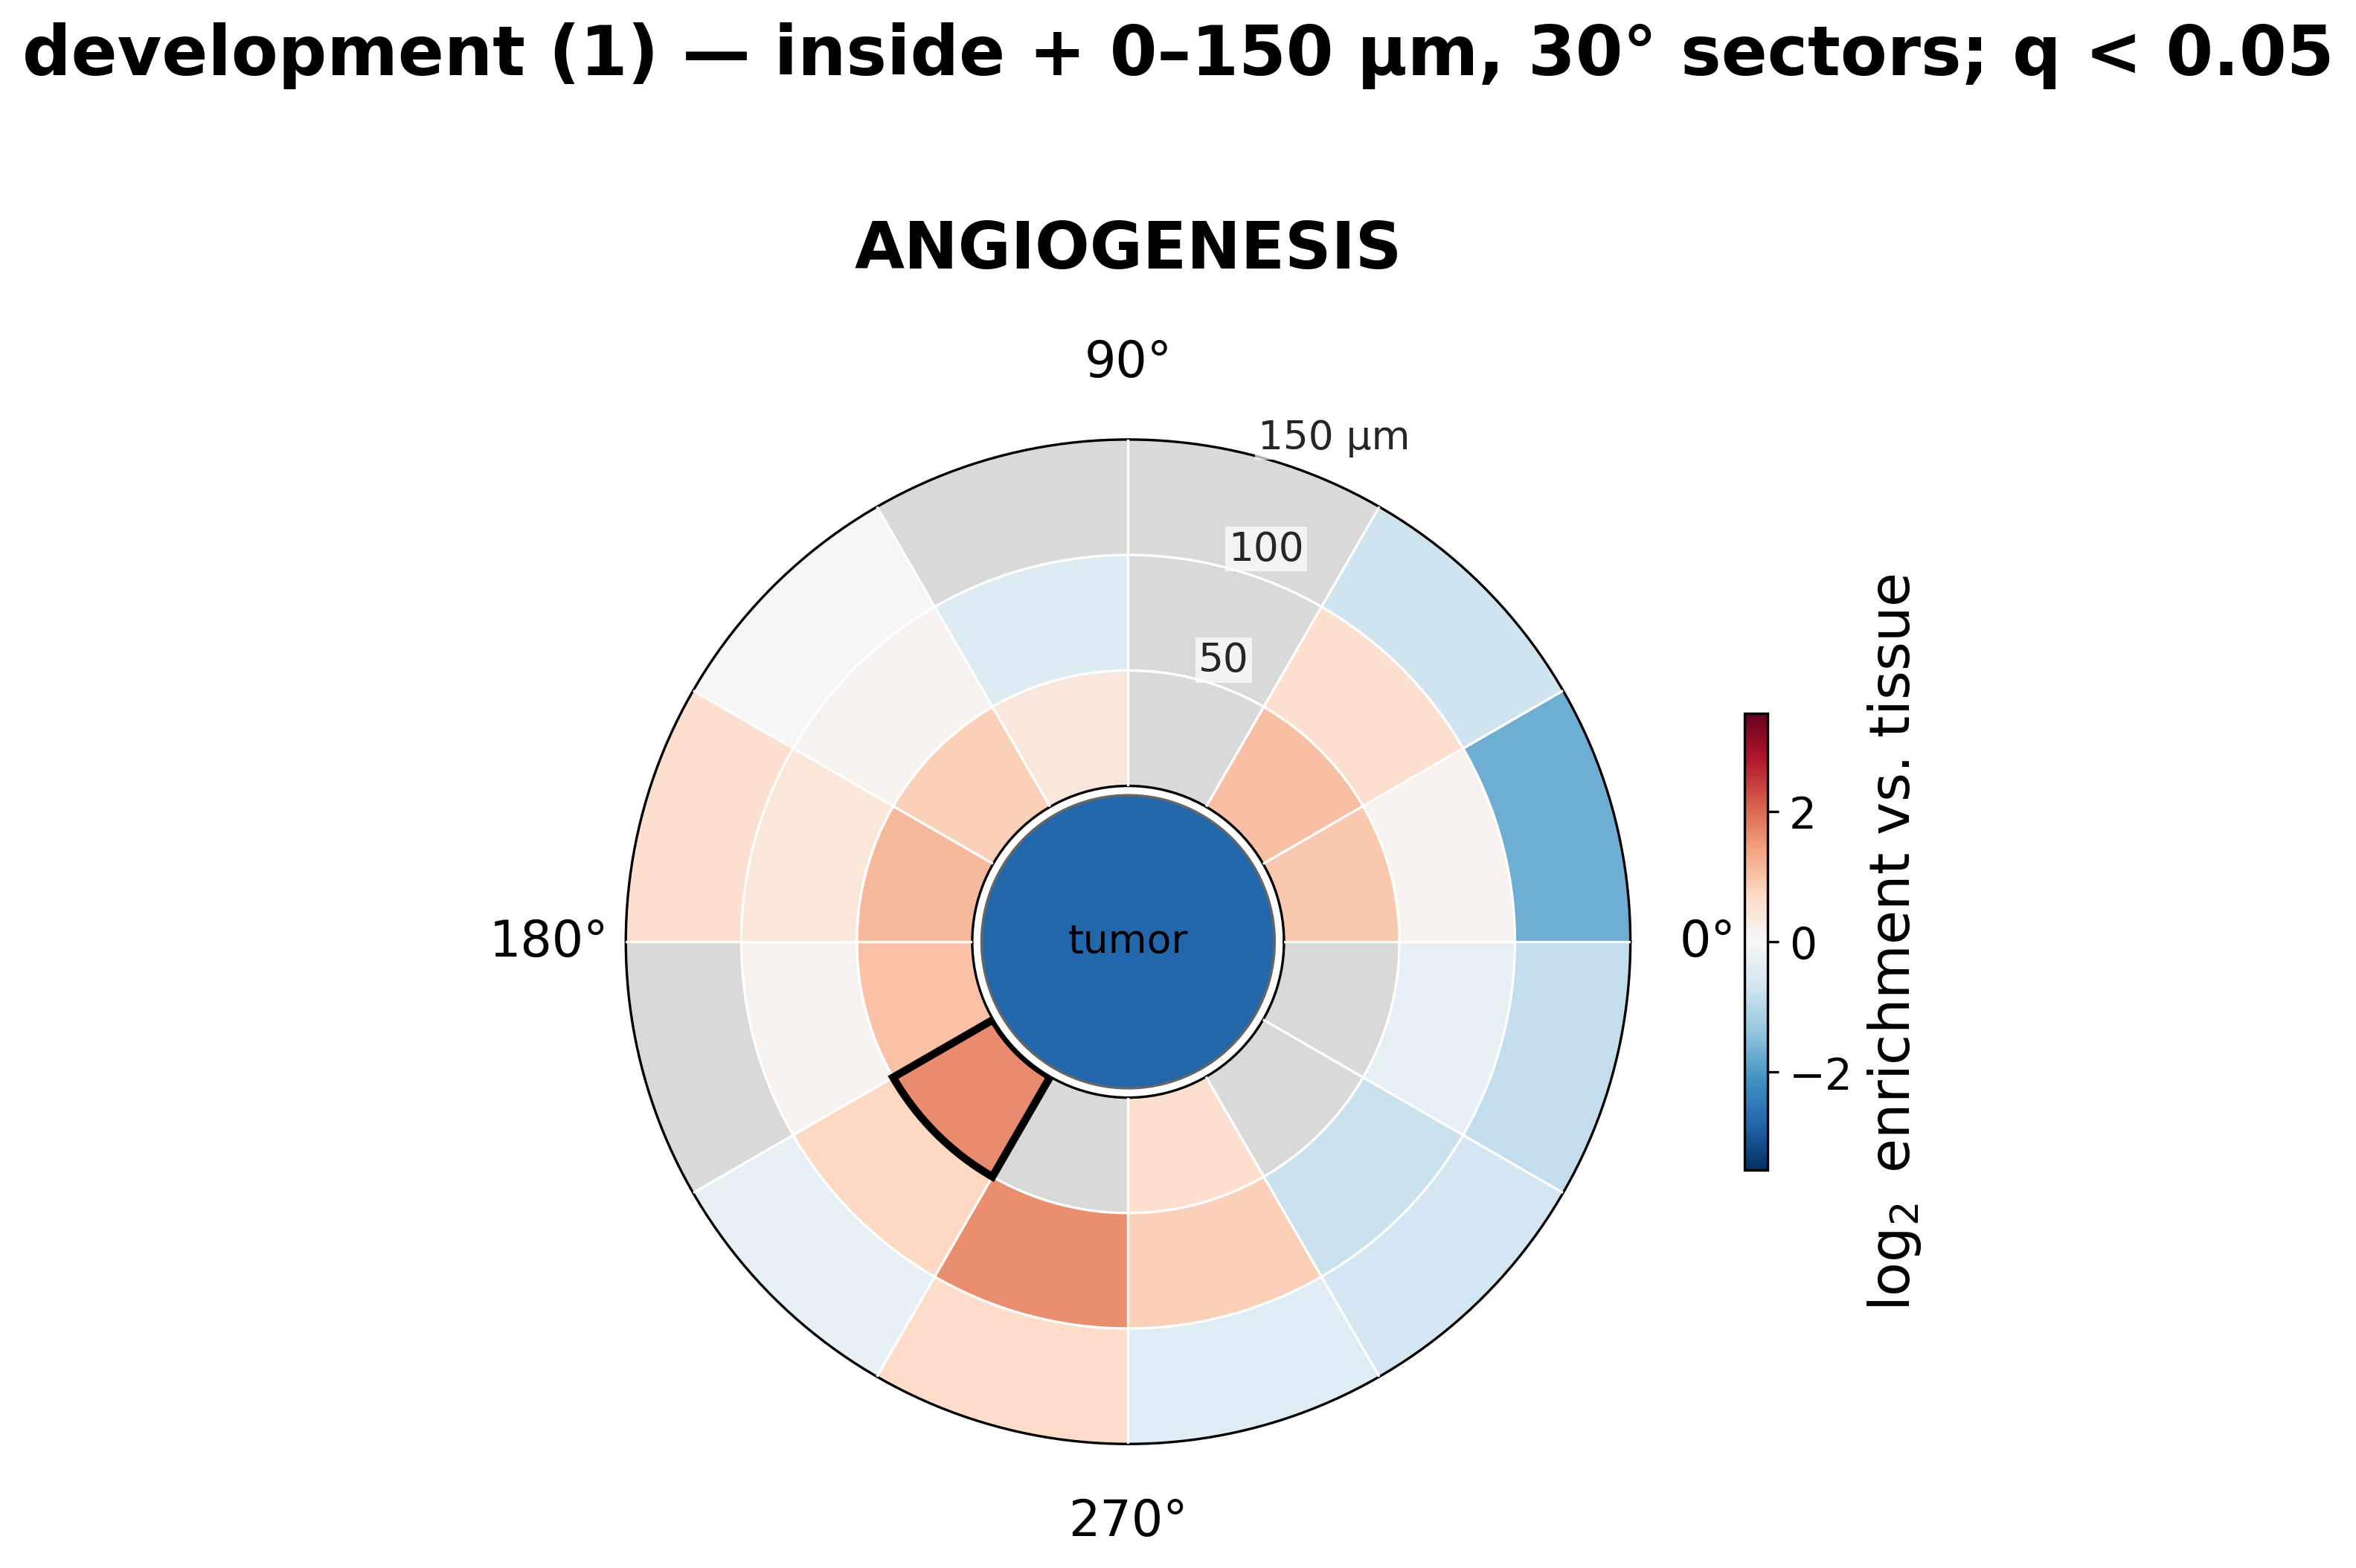

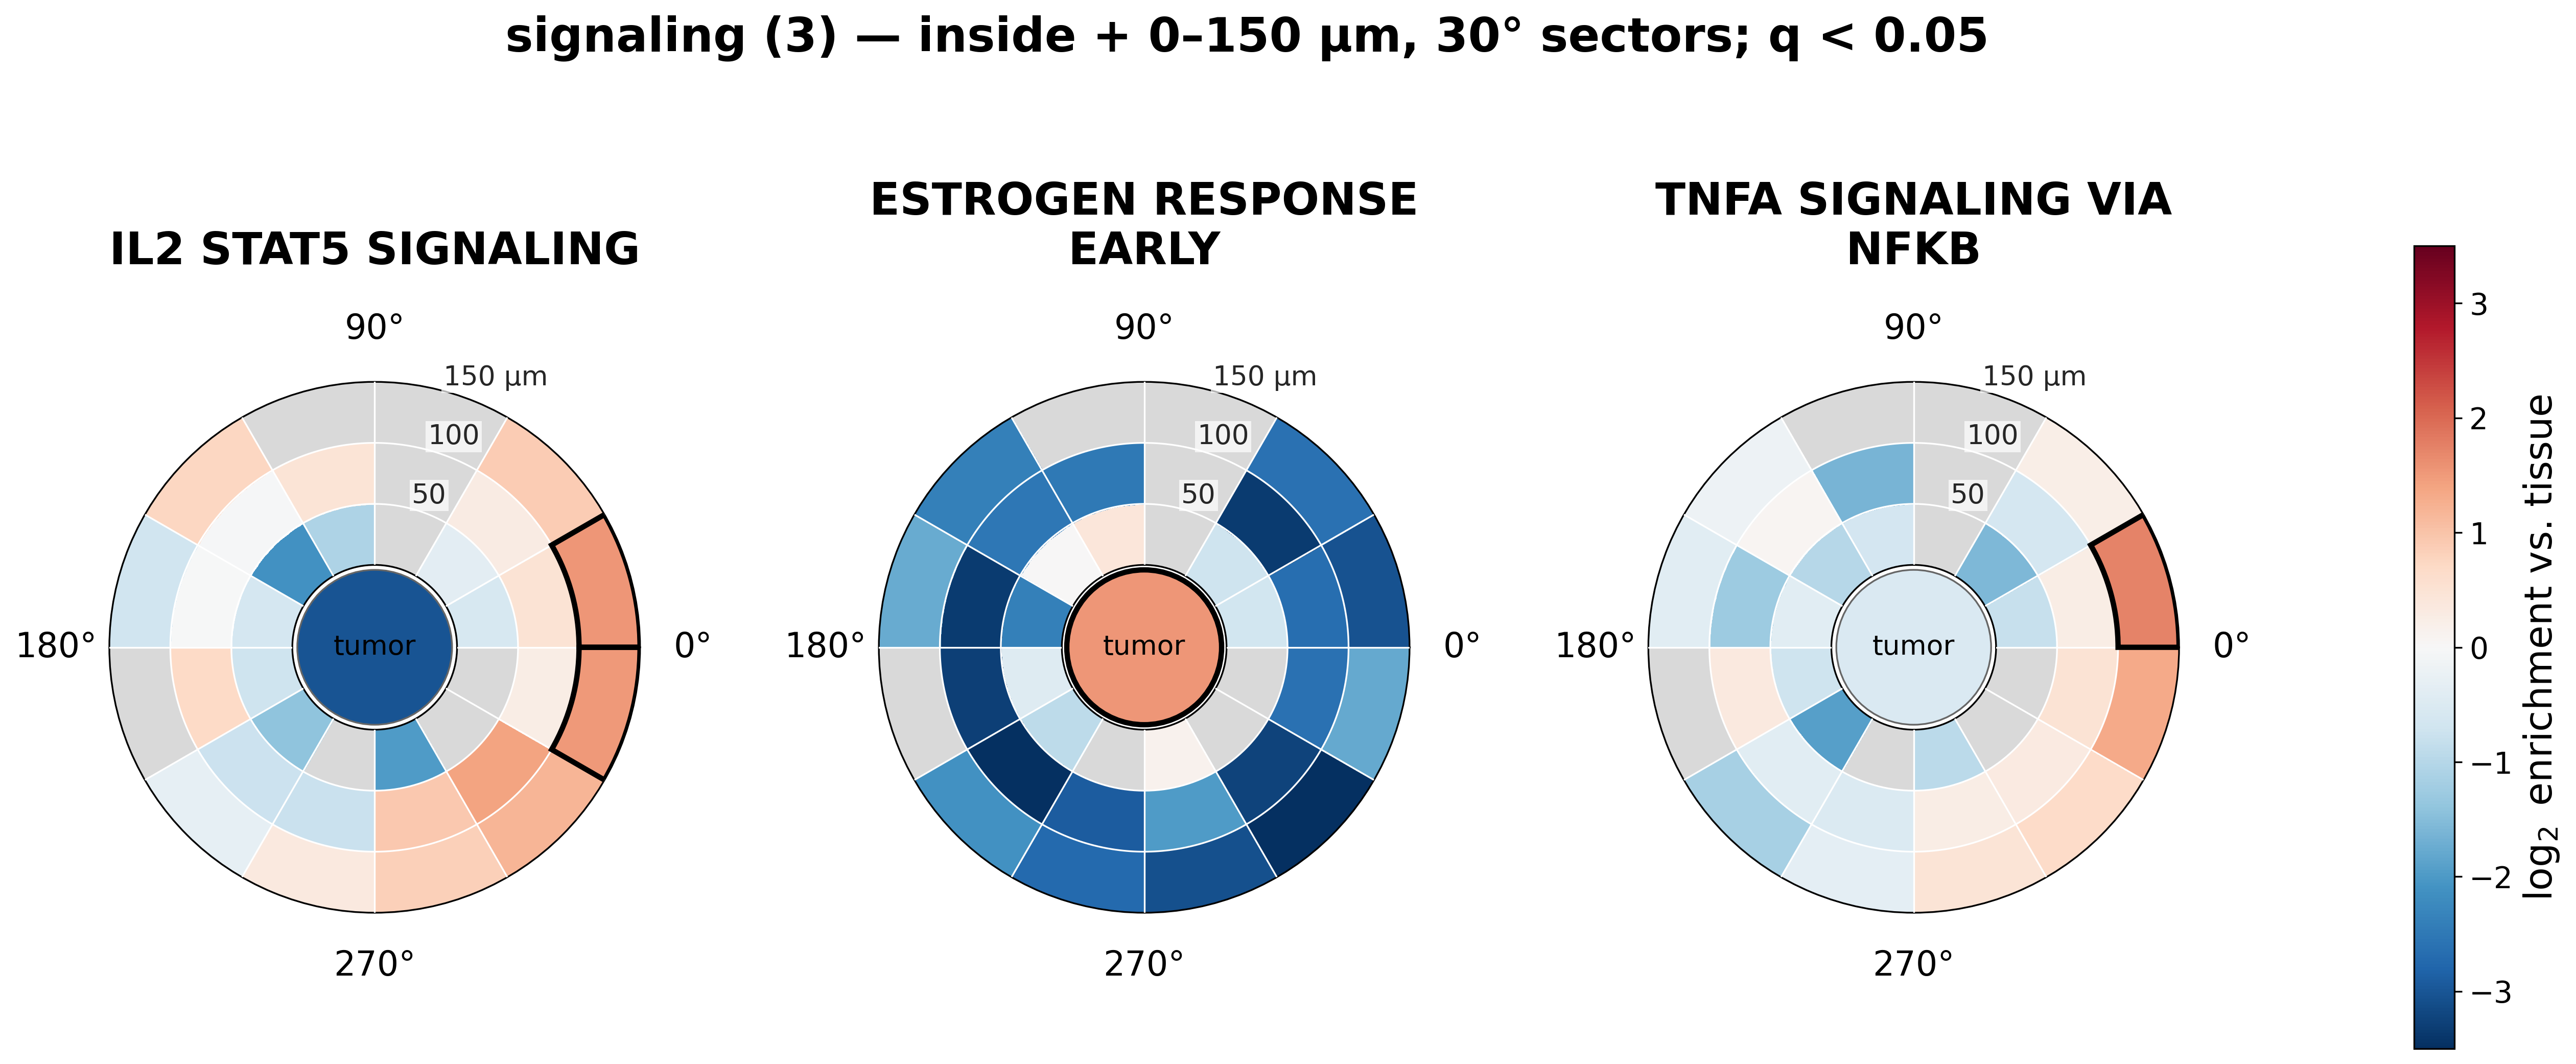

In [8]:
figs = scomv.plot_significant_hallmarks(hm, q_key="q", by_category=True)
plt.show()

## 4. A single tumor solid

Any ROI with shortest vectors works. `scomv.PolarROI.from_solid` takes one solid of `scomv.tumor_solid` (see the
tumor_solid_analysis tutorial), e.g. `hallmark_polar_enrichment(PolarROI.from_solid(grid, solid, 12), r_max=150)`.